<a href="https://colab.research.google.com/github/Allankamaus/SemProject_MLEngine/blob/master/Car_Price_Prediction_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preparation

In [1]:
pip install pandas numpy scikit-learn matplotlib seaborn streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


# Data Ingestion

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Load CSV
DATA_PATH="./data/CAR DETAILS FROM CAR DEKHO.csv"
df = pd.read_csv(DATA_PATH)

print("DATASET TOPOLOGY AUDIT")
print("Dataset Shape:", df.shape)
print("\nColumn Information & Data Types:")
print(df.info())
print("\nFirst 5 rows:")
print(df.head())

DATASET TOPOLOGY AUDIT
Dataset Shape: (4340, 8)

Column Information & Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB
None

First 5 rows:
                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000   

# Data Hygiene & Missing Value Strategy

In [4]:
print("Data Hygiene & Cleaning")
print("Missing values per column:\n", df.isnull().sum())
print("Number of duplicate rows:", df.duplicated().sum())

# Drop duplicates to prevent train-test data leakage
df = df.drop_duplicates().reset_index(drop=True)

# Filter obvious listing anomalies ( e.g selling price <= 0 or outliers )
df = df[df["selling_price"] > 10000]
df = df[df["km_driven"] > 100]

print("Cleaned Dataset Shape:",df.shape)

Data Hygiene & Cleaning
Missing values per column:
 name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64
Number of duplicate rows: 763
Cleaned Dataset Shape: (3576, 8)


# Exploratory Data Analysis

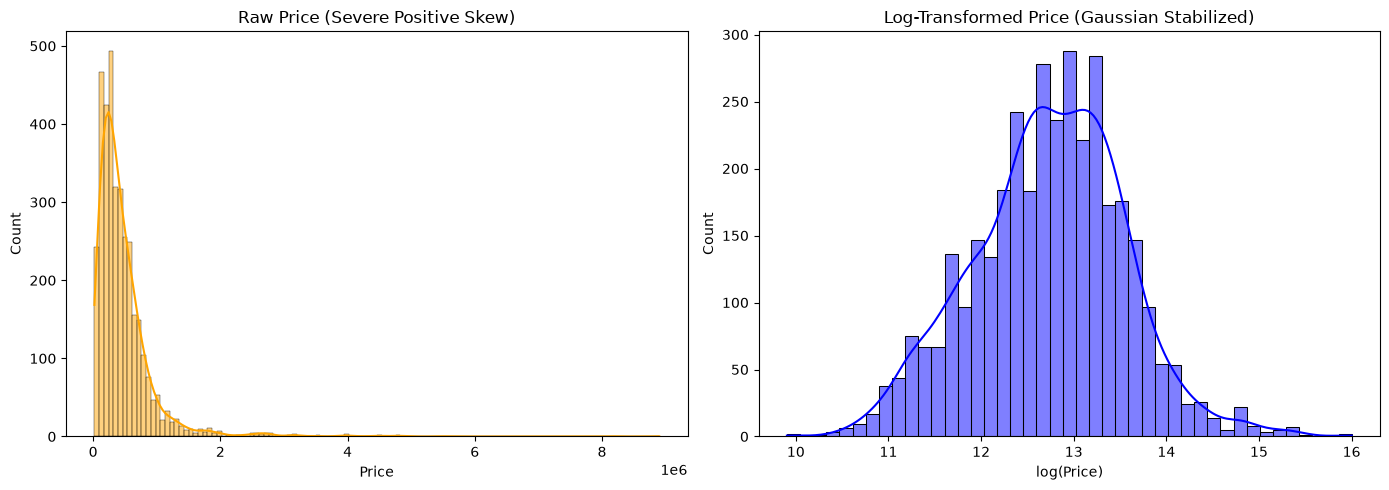

In [5]:
fig, axes = plt.subplots(1,2,figsize=(14,5))

# Plot raw  right-skewed price distribution
sns.histplot(df["selling_price"],kde=True,ax=axes[0], color="orange")
axes[0].set_title("Raw Price (Severe Positive Skew)")
axes[0].set_xlabel("Price")

# Plot log-transformed price distribution
sns.histplot(np.log(df["selling_price"]), kde=True, ax=axes[1], color="blue")
axes[1].set_title("Log-Transformed Price (Gaussian Stabilized)")
axes[1].set_xlabel("log(Price)")

plt.tight_layout()
plt.show()

# Extract target and apply log transform to protect backpropagation gradient updates
y = np.log(df["selling_price"])

# Feature Engineering & Preprocessing Pipeline

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Feature Engineering
CURRENT_YEAR = 2024
df["brand"] = df["name"].apply(lambda x: x.split()[0])
df["vehicle_age"] = CURRENT_YEAR - df["year"]
df["km_per_year"] = df["km_driven"] / (df["vehicle_age"] + 1)

# Group uncommon brands into "Other" to keep things manageable
top_brands = df["brand"].value_counts().nlargest(10).index
df["brand"] = df["brand"].apply(lambda b: b if b in top_brands else "Other")

categorical_features = ["brand","fuel","seller_type","transmission","owner"]
numeric_features = ["vehicle_age","km_driven","km_per_year"]

X = df[categorical_features + numeric_features]

# Train/Test Split (80% Train, 20% Holdout Test)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

# Robust Column Transformer Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

# Fit and transform
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessed Input Tensor Dimensions:")
print("Training Features:", X_train_processed.shape)
print("Testing Features:",X_test_processed.shape)

Preprocessed Input Tensor Dimensions:
Training Features: (2860, 29)
Testing Features: (716, 29)
